## Authors: Jonathan Yik Chang Ting

**email:** Jonathan.Ting@anu.edu.au

# Required Packages

- numpy
- scipy.optimize
- matplotlib
- pandas

In [20]:
%load_ext autoreload
%autoreload 2

import pickle 

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.datasets import load_diabetes, make_blobs
from sklearn.metrics import explained_variance_score
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

# from archetypes import *
from spams import archetypalAnalysis


sns.set_style('ticks')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Load Data

In [33]:
# Global variables
NUM_SAMPLES = 3000
NUM_ARCHETYPES = 8
NUM_FOLD = 3
DATASET_TYPE = 'blob'

ROBUST = False  # Whether to use modified AA algorithm to deal with outliers
SHUFFLE = True  # Whether to shuffle data before splitting
RANDOM_STATE = 42
VERBOSE = True

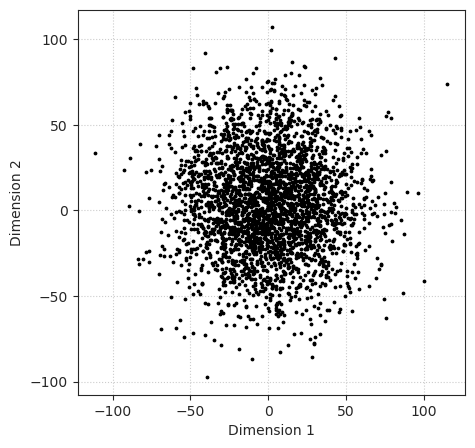

In [34]:
# Generate data
if DATASET_TYPE == 'uniformSquare':
    x = np.random.uniform(-10, 10, NUM_SAMPLES)
    y = np.random.uniform(-10, 10, NUM_SAMPLES)
    z = np.random.uniform(-10, 10, NUM_SAMPLES)
    X = np.array([[xi, yi] for xi, yi in zip(x, y)])
elif DATASET_TYPE == 'uniformCube':
    x = np.random.uniform(-10, 10, NUM_SAMPLES)
    y = np.random.uniform(-10, 10, NUM_SAMPLES)
    z = np.random.uniform(-10, 10, NUM_SAMPLES)
    X = np.array([[xi, yi, zi] for xi, yi, zi in zip(x, y, z)])
elif DATASET_TYPE == 'blob':
    X, y_true = make_blobs(n_samples=NUM_SAMPLES, centers=1, cluster_std=30, random_state=0)
elif DATASET_TYPE == 'diabetes':
    diabetes = load_diabetes()
    X, y = diabetes.data, diabetes.target
    print(f"Features: {diabetes.feature_names}")
elif DATASET_TYPE == 'bnp':
    eleComb = 'PdPt'
    with open(f"data/dfScaledNoLVHCs/dfScaledNoLVHC_{eleComb}_V1C99.pickle", 'rb') as f: 
        dfNormalised = pickle.load(f)
    X = dfNormalised.iloc[:, :-2].values
    print(f"Columns: {dfNormalised.columns}")

# Visualise data (plot first two dimensions)
plt.figure(figsize=(5, 5))
plt.scatter(X[:, 0], X[:, 1], s=3, c='k')
plt.grid(linestyle='dotted')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')

# Standardise data
sc = StandardScaler()
Xscaled = sc.fit_transform(X)

# General Functions

In [23]:
def runAAonWholeData(Xscaled, 
                     numArchetypes=4, robust=False,
                     verbose=False):
    Zclassical, A, B = archetypalAnalysis(np.asfortranarray(Xscaled.T), p=numArchetypes, returnAB=True, robust=robust, epsilon=0.001, randominit=False)
    Xapprox = np.matmul(Zclassical, A.toarray())
    expVarClassical = explained_variance_score(Xscaled, Xapprox.T)
    if verbose:
        print(f"\nExplained variance: {expVarClassical:.4f}")
        print(f"Archetype set:\n{Zclassical}")
    return Zclassical, expVarClassical

In [24]:
def runAAonSplitData(Xscaled, 
                     numArchetypes=4, robust=False,
                     numSplits=4, shuffle=True, randomState=42, verbose=False):
    kFold = KFold(n_splits=numSplits, shuffle=shuffle, random_state=randomState)
    allArchetypes, allAlphas, allTestIndices = [], [], []
    for (i, (_, testIndices)) in enumerate(kFold.split(Xscaled)):
        Xfold = Xscaled[testIndices, :]
        Z, A, B = archetypalAnalysis(np.asfortranarray(Xfold.T), p=numArchetypes, returnAB=True, robust=robust, epsilon=0.001, randominit=False)
        Xapprox = np.matmul(Z, A.toarray())
        expVar = explained_variance_score(Xfold, Xapprox.T)
        # Store outputs
        allArchetypes.append(Z)
        allAlphas.append(A.toarray())
        allTestIndices.append(testIndices)
        if verbose:
            print(f"  Data subset {i+1} explained variance: {expVar:.4f}")
            print(f"  Data subset {i+1} archetypes:\n{Z}")
    return allArchetypes, allAlphas, allTestIndices

In [25]:
def expVarFromArchetypes(allArchetypes, allAlphas, Xscaled, 
                         runFinalAA=True,
                         numArchetypes=4, robust=False, 
                         verbose=False):
    if not runFinalAA:  # Without running another time of archetypal analysis
        ZcombinedSet, Xapproxs = None, []
        for i in range(len(allArchetypes)):
            XfoldApprox = np.matmul(allArchetypes[i], allAlphas[i])
            Xapproxs.append(XfoldApprox)
        XfinalApprox = np.concatenate(Xapproxs, axis=1)
        if verbose:
            print(f"Explained variance with all archetypes from split subsets: {explained_variance_score(Xscaled, XfinalApprox.T):.4f}")
            print(f"All archetypes:\n{allArchetypes}")

    # Extract final set of archetypes from the collected archetypes
    archetypes = np.concatenate(allArchetypes, axis=1)
    Ziterative, A, B = archetypalAnalysis(np.asfortranarray(archetypes), p=numArchetypes, returnAB=True, robust=robust, epsilon=0.001, randominit=False)
    Zapprox = np.matmul(Ziterative, A.toarray())
    expVarIterative = explained_variance_score(archetypes, Zapprox)
    if verbose:
        print(f"\nExplained variance with archetypes extracted from all archetypes: {expVarIterative:.4f}")
        print(f"Final archetypes:\n{Ziterative}")
    return Ziterative, expVarIterative, archetypes

In [26]:
def plotAAoutputs(Xscaled, Zclassical, expVarClassical, Ziterative, expVarIterative, allTestIndices, archetypes, 
                  plotSubsets=True, figName='',
                  figSize=(7, 4), dpi=300, verbose=False):
    """Plot the data and archetypes from both approaches."""
    if verbose:
        print(f"Archetype set from classical approach:\n{Zclassical}")
        print(f"Archetype set from iterative approach:\n{Ziterative}")
    
    plt.figure(figsize=figSize, dpi=dpi)
    if not plotSubsets:
        plt.scatter(Xscaled[:, 0], Xscaled[:, 1], marker='.', s=5) # color='y', 
    else:
        for testIndices in allTestIndices: 
            plt.scatter(Xscaled[testIndices, 0], Xscaled[testIndices, 1], marker='.', s=5)
    plt.plot(Zclassical[0, :], Zclassical[1, :], 'X', markersize=9, markeredgecolor='k', markeredgewidth=0.8, color='r', alpha=0.5)  # color='m'
    plt.plot(Ziterative[0, :], Ziterative[1, :], 'X', markersize=9, markeredgecolor='k', markeredgewidth=0.8, color='b', alpha=0.5)  # color='c'
    plt.plot(archetypes[0, :], archetypes[1, :], 'D', markersize=4, markeredgecolor='k', markeredgewidth=0.6, color='y')  # color='b'
    plt.xlabel('x')
    plt.ylabel('y')
    plt.grid(linestyle='dotted')
    legendEntries = [f"Data Subset {i+1}" for i in range(len(allTestIndices))] if plotSubsets else ['Data']
    legendEntries += [f"Classical Approach Archetypes, ExpVar: {expVarClassical:.3f}", f"Iterative Approach Archetypes, ExpVar: {expVarIterative:.3f}", 'Archetypes from Split Sets']
    plt.legend(legendEntries, loc='center left', bbox_to_anchor=(1, 0.5), ncol=1, fancybox=True, shadow=False, fontsize='x-small')
    plt.tight_layout()
    plt.savefig(f"figures/AA_{figName}.png")

RSS FISTA = 1046.5896
RSS FISTA = 447.07402
RSS FISTA = 259.63994
RSS AS = 174.31457
RSS AS = 76.705306
RSS AS = 22.341614
RSS AS = 2.6920619
RSS AS = 1.5460597
RSS AS = 1.1819354
RSS AS = 1.0252618
RSS AS = 0.97853778
RSS AS = 0.93502707
RSS AS = 0.89444096
RSS AS = 0.85659313
RSS AS = 0.82132219
RSS AS = 0.78846784
RSS AS = 0.75788077
RSS AS = 0.7294126
RSS AS = 0.70291732
RSS AS = 0.67826688
RSS AS = 0.6551693
RSS AS = 0.63341032
RSS AS = 0.61290892
RSS AS = 0.59360349
RSS AS = 0.57542091
RSS AS = 0.5582935
RSS AS = 0.54216291
RSS AS = 0.52697106
RSS AS = 0.51259492
RSS AS = 0.49894912
RSS AS = 0.49178278
RSS AS = 0.49142891
RSS AS = 0.49108788
RSS AS = 0.49075006
RSS AS = 0.4904153
RSS AS = 0.49008352
RSS AS = 0.4897547
RSS AS = 0.48942873
RSS AS = 0.48910555
RSS AS = 0.48878512
RSS AS = 0.4884674
RSS AS = 0.48815232
RSS AS = 0.48783981
RSS AS = 0.48752984
RSS AS = 0.48722235
RSS AS = 0.48691728
RSS AS = 0.4866146
RSS AS = 0.48631425
RSS AS = 0.48601616
RSS AS = 0.48572027
RSS AS =

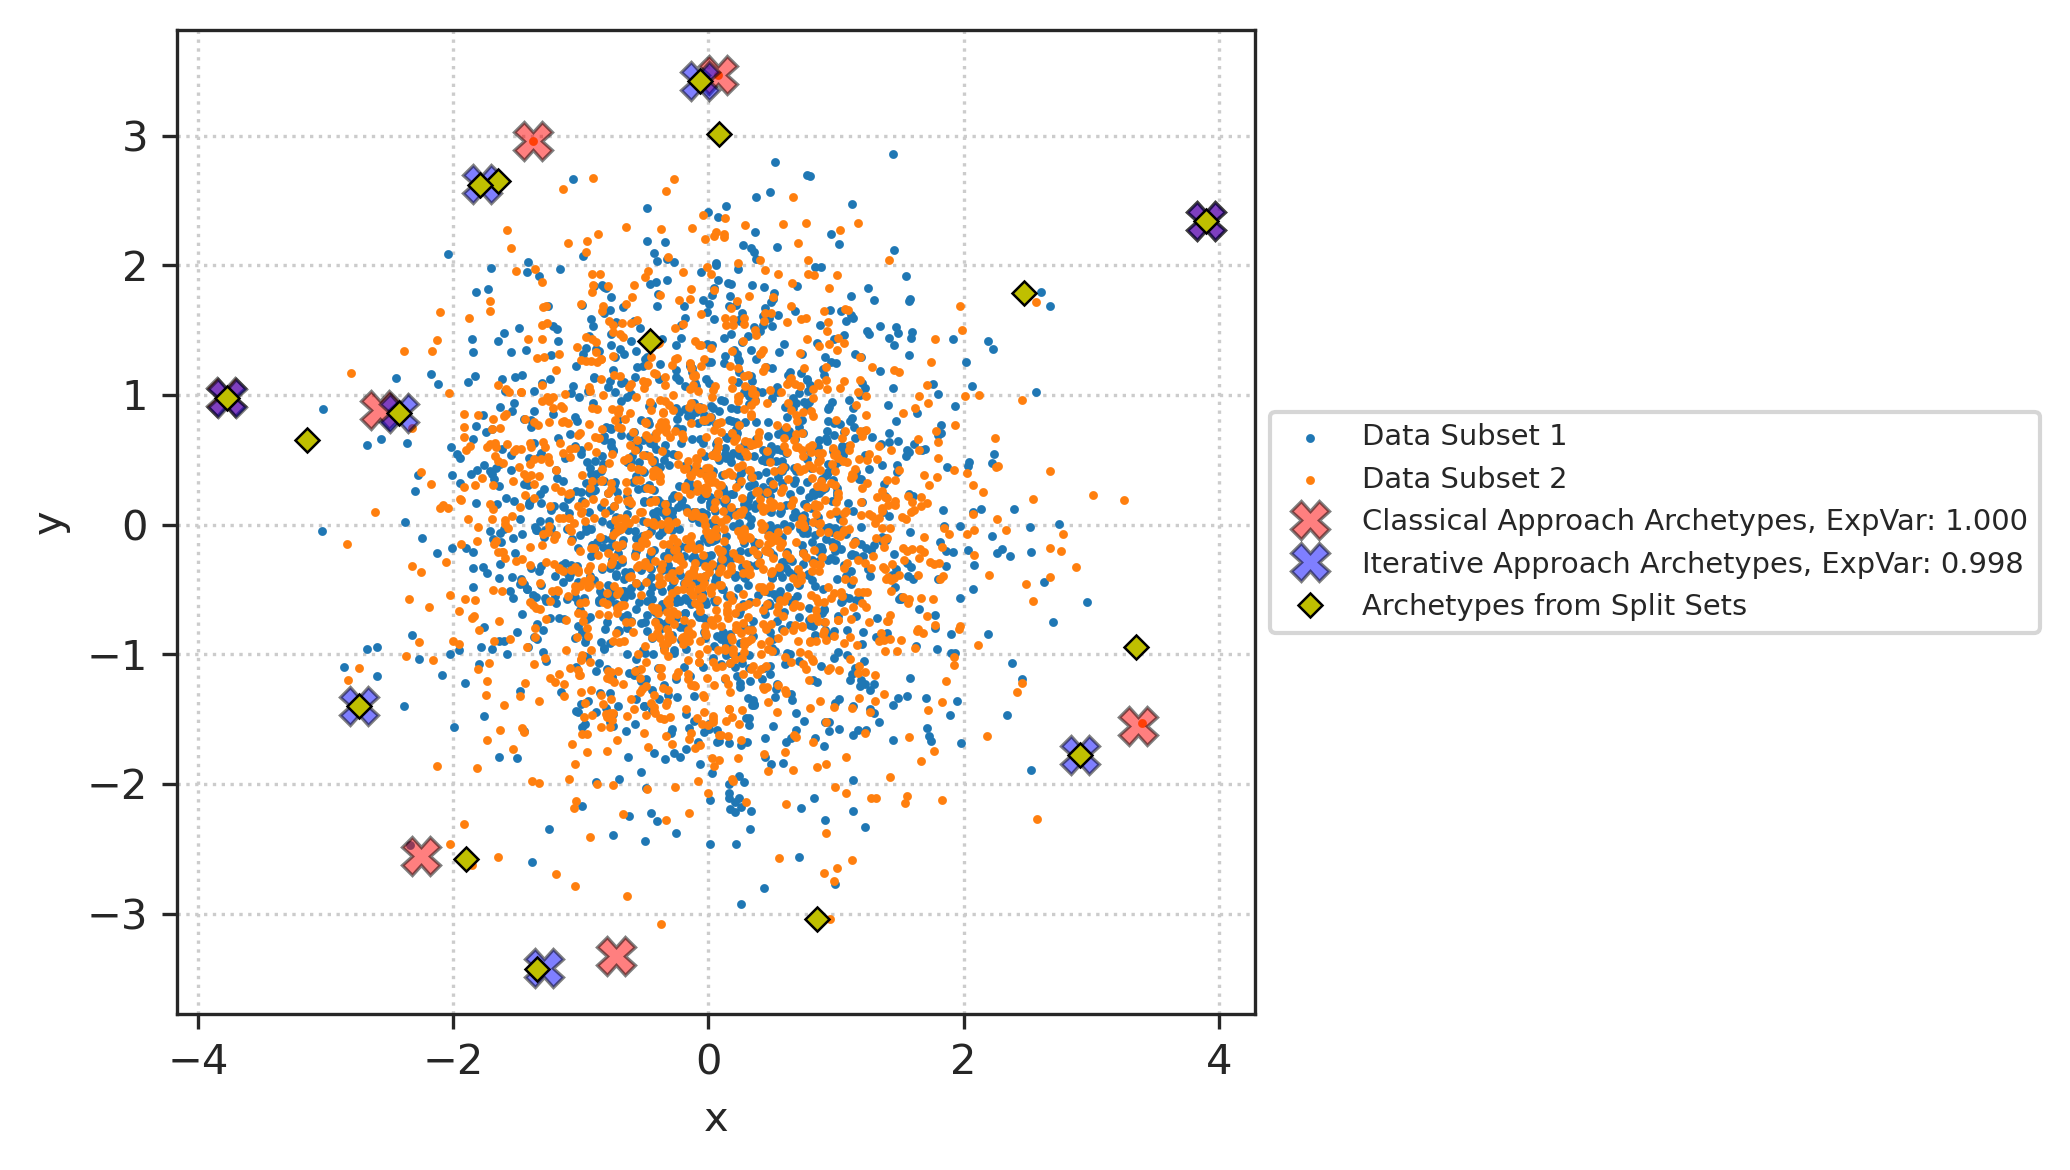

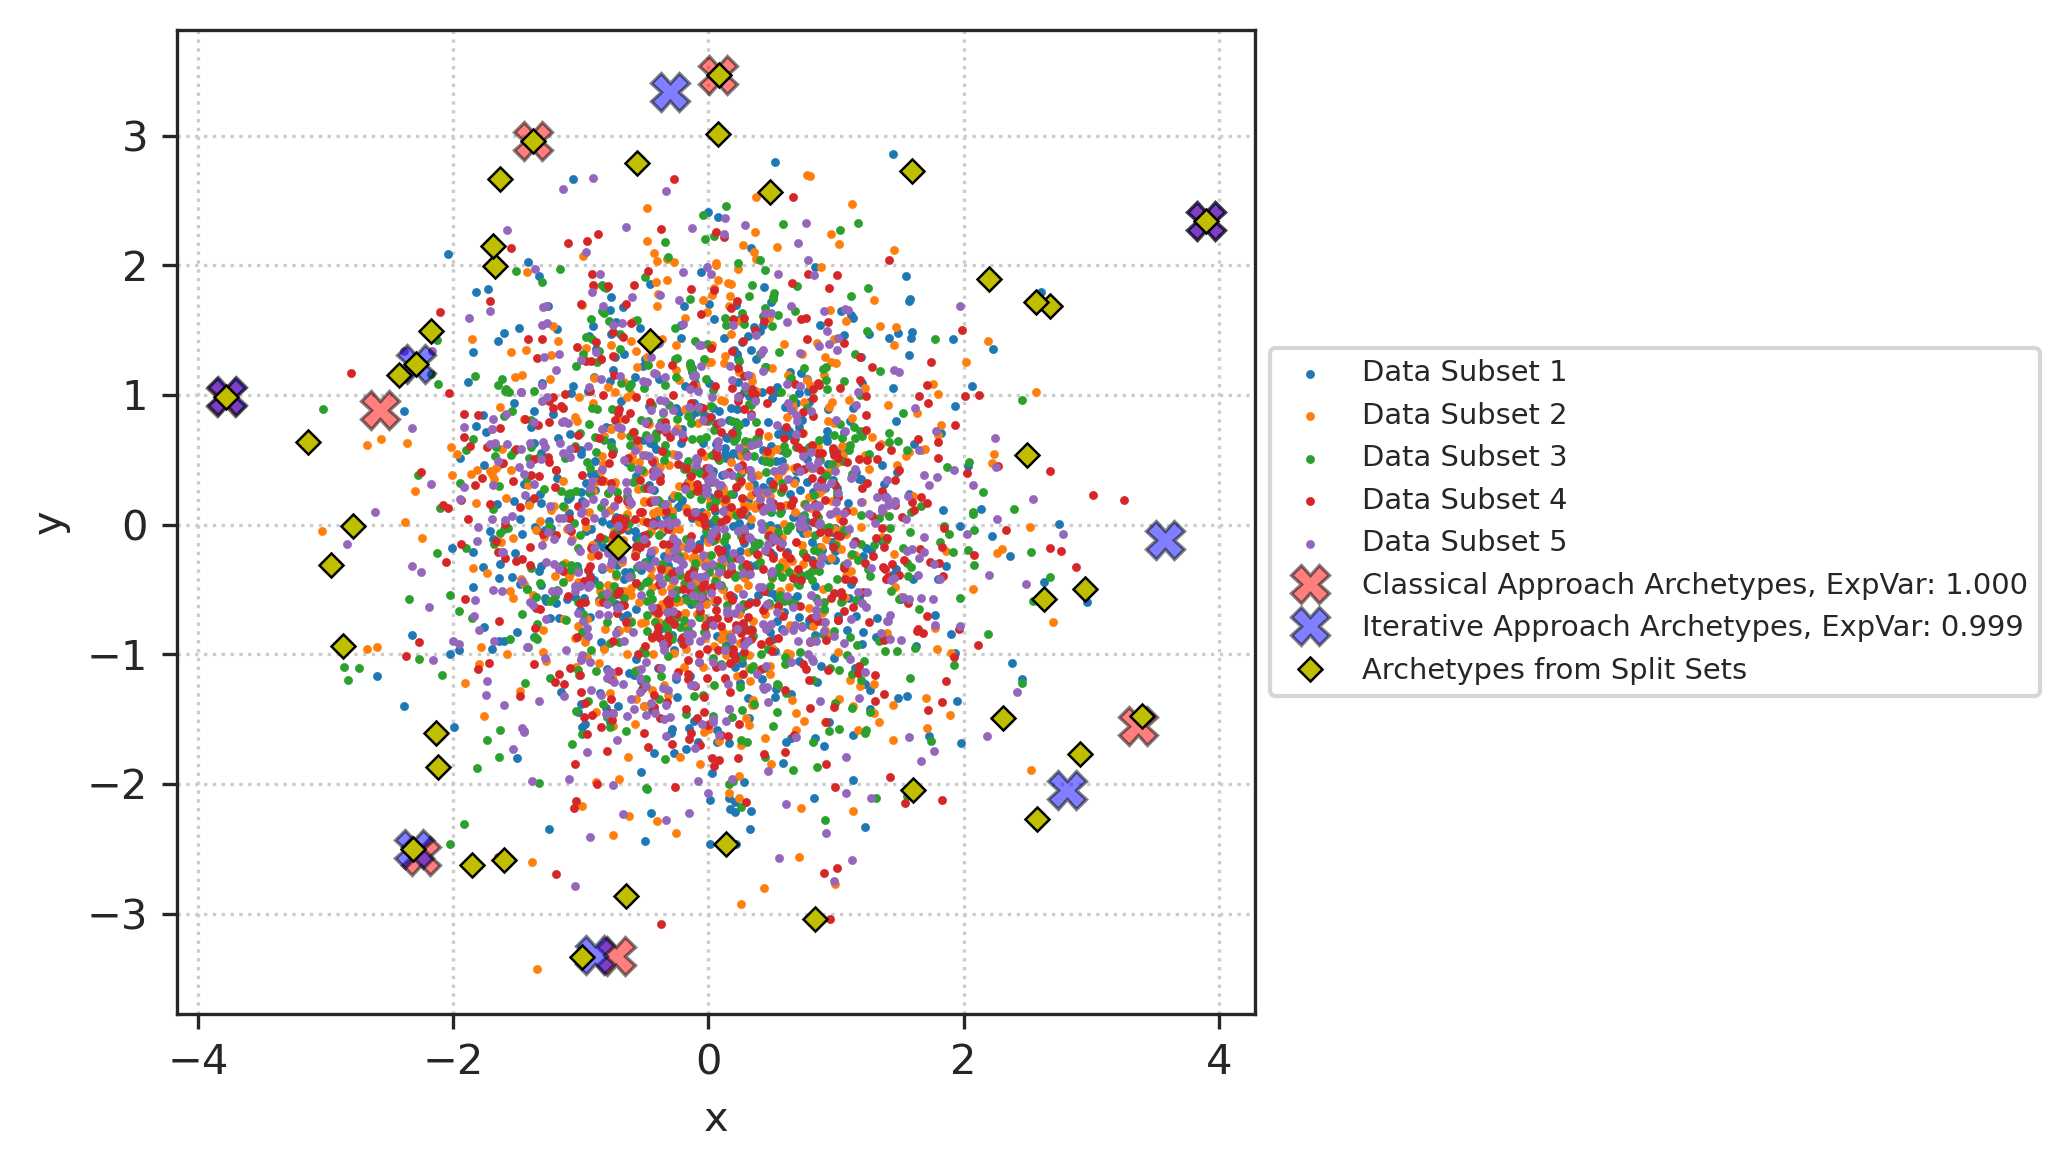

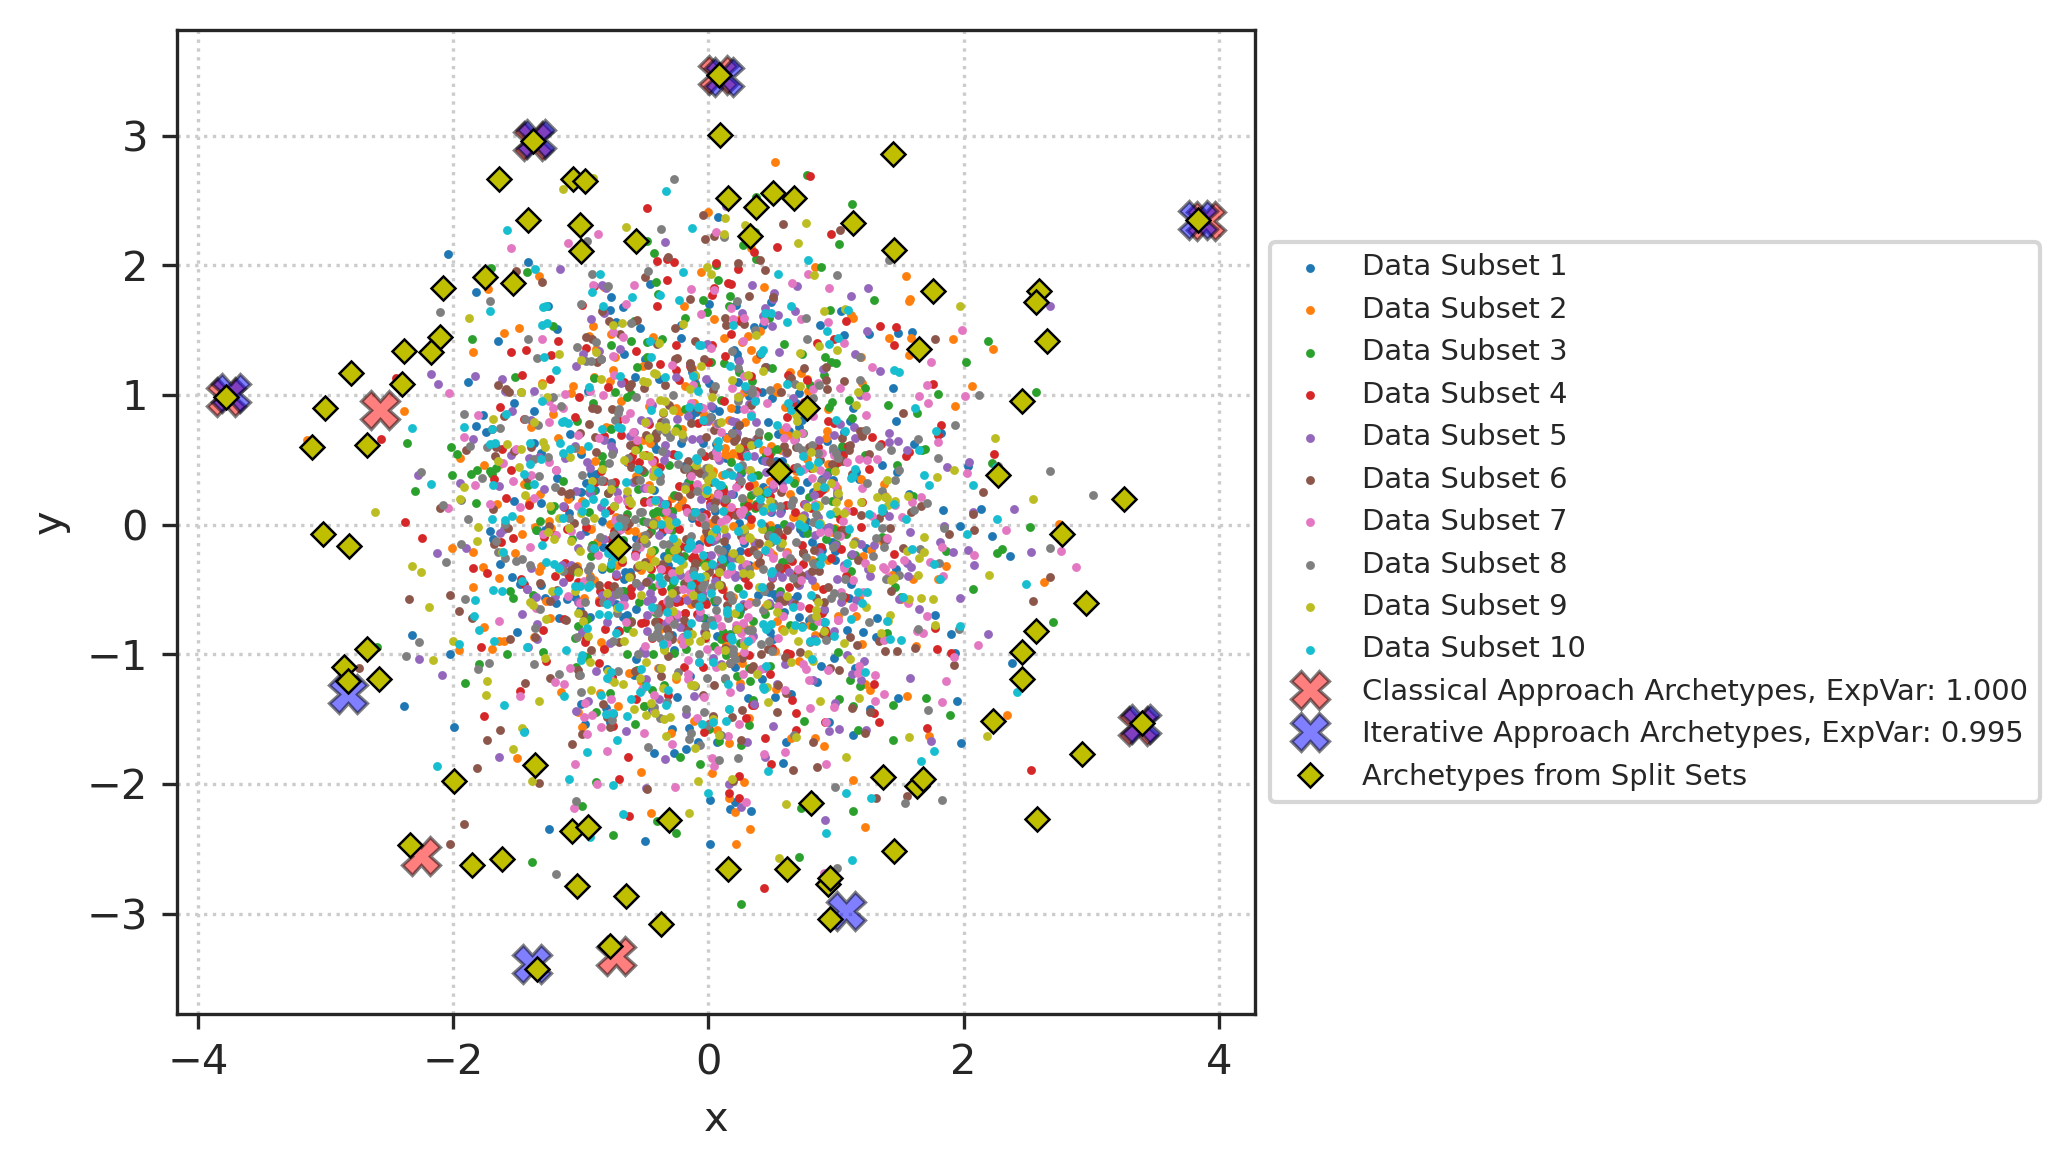

In [35]:
def runAAonData(Xscaled, 
                numArchetypes=4, robust=False, 
                numFolds=[4], shuffle=True, randomState=42, 
                datasetType='uniformSquare', plotSubsets=True, 
                figSize=(7, 4), dpi=300, verbose=False):
    Zclassical, expVarClassical = runAAonWholeData(Xscaled, numArchetypes=numArchetypes, robust=robust, verbose=verbose)
    # Elbow plot for iterative approach
    Ziteratives, expVarIteratives = [], []
    for (i, numFold) in enumerate(numFolds):
        allArchetypes, allAlphas, allTestIndices = runAAonSplitData(Xscaled, 
                                                                    numArchetypes=numArchetypes, robust=robust, 
                                                                    numSplits=numFold, shuffle=shuffle, randomState=randomState, verbose=verbose)
        Ziterative, expVarIterative, archetypes = expVarFromArchetypes(allArchetypes, allAlphas, Xscaled, 
                                                                       runFinalAA=True,
                                                                       numArchetypes=numArchetypes, robust=robust, 
                                                                       verbose=verbose)
        colourSubsetsStr = 'colourSubsets' if plotSubsets else 'colourWholeSet'
        plotAAoutputs(Xscaled, Zclassical, expVarClassical, Ziterative, expVarIterative, allTestIndices, archetypes, 
                      plotSubsets=plotSubsets, figName=f"{datasetType}_{numFold}-fold_{colourSubsetsStr}",
                      figSize=figSize, dpi=dpi, verbose=verbose)
        Ziteratives.append(Ziterative)
        expVarIteratives.append(expVarIterative)
    
    return Zclassical, expVarClassical, Ziteratives, expVarIteratives

numFolds = [2, 5, 10]
Zclassical, expVarClassicals, Ziteratives, expVarIteratives = runAAonData(Xscaled, 
                                                                          numArchetypes=NUM_ARCHETYPES, robust=ROBUST, 
                                                                          numFolds=numFolds, shuffle=SHUFFLE, randomState=RANDOM_STATE,
                                                                          datasetType=DATASET_TYPE, plotSubsets=True,
                                                                          figSize=(7, 4), dpi=300, verbose=VERBOSE)

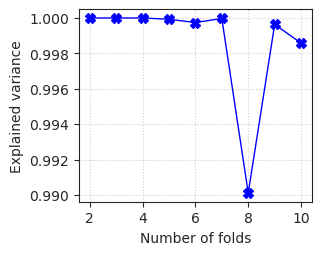

In [9]:
# plt.figure(figsize=(3, 2.5), dpi=100)
# plt.plot(numFolds, expVarIteratives, marker='X', markersize=7, linewidth=1, color='b')
# plt.xlabel('Number of folds')
# plt.ylabel('Explained variance')
# plt.grid(linestyle='dotted')

# Selecting number of archetypes with elbow plot

**.archetype_profile** provides the profile of the archetypes. It shows each archetype is high in which features and low in which. **.archetype_profile** has similar shape to **.archetypes**. Further, the numbers are between 0 to 1. You can multiply it by 100 to convert them to percentange. 

In [ ]:
AA.archetype_profile

array([[0.86      , 0.99666667, 0.00333333, 0.27666667, 0.67666667],
       [0.01      , 0.50666667, 0.80666667, 0.01      , 0.99666667]])

## Simplex plot: Mapping datapoints to archetype convex hull

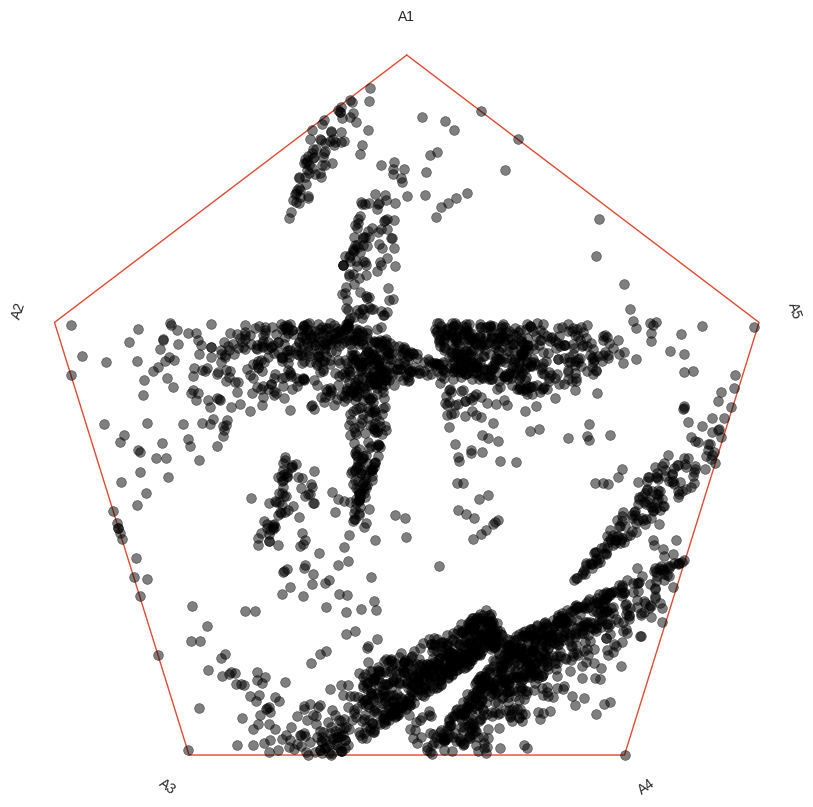

In [283]:
AA.plot_simplex(AA.alfa)

In [90]:
df_args = df[['Gender']]

In [98]:
df_args['color'] = 'red'
df_args.loc[:]['color'][df_args['Gender']=='female'] = 'blue'

df_args['marker'] = 'v'
df_args.loc[:]['marker'][df_args['Gender']=='female'] = 's'

df_args['size'] = df[['Height']]

plot_args = {'color': df_args['color'], 's': df_args['size'], 'marker': df_args['marker']}
df_args

/tmp/ipykernel_860267/3979262807.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_args['color'] = 'red'
/tmp/ipykernel_860267/3979262807.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_args['marker'] = 'v'
/tmp/ipykernel_860267/3979262807.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.ht

,Gender,color,marker,size
0,male,red,v,174.0
1,male,red,v,175.3
2,male,red,v,193.5
3,male,red,v,186.5
4,male,red,v,187.2
...,...,...,...,...
502,female,blue,s,176.5
503,female,blue,s,164.4
504,female,blue,s,160.7
505,female,blue,s,174.0


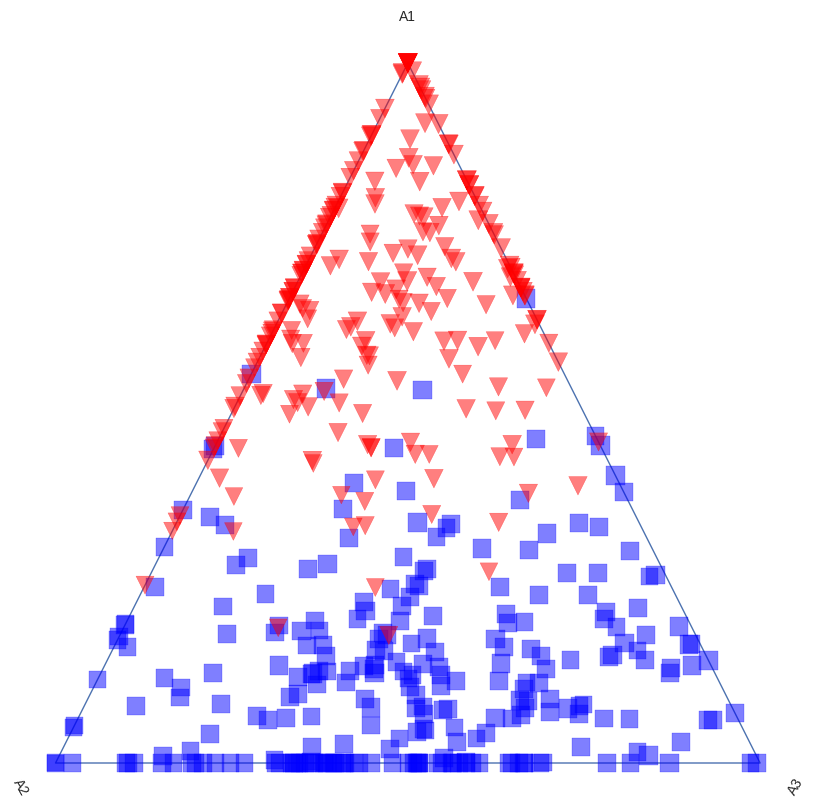

In [97]:
AA.plot_simplex(AA.alfa, plot_args)

# More flexibilty to visualise data in Simplex Plots

Additional utility functions are included in the package to give more flexibities to create simplex plots and color the data points in different fashions. To do this, three steps should be taken. First, you need to create the simplex plot frame with **create_simplex_ax** utility function, then you need to map the **alfa** values to the simplex frame using the **map_alfa_to_simplex** utility function, at last you can use standard matplotlib scatter plot to visualise data points. Let's see how it works.

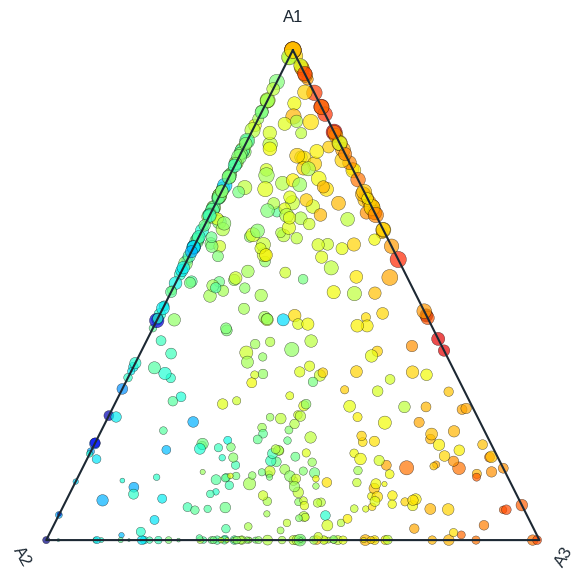

In [100]:
# STEP 1: Create Simplex plot. You can control the color of gridlines and borders (edges) of the simplex plots. 
# You can also control the fontcolor as well as figure size
create_simplex_ax(AA, grid_on = True, 
                  gridcolor = '#EAECEE', 
                  bordercolor='#1C2833', 
                  fontcolor = '#1C2833',
                  fig_size=[7,7])

# STEP 2: Map the alfa values to simplex plot
mapped_alfa = map_alfa_to_simplex(AA.alfa, AA)

# STEP 3: Use scatter plots to add the mapped alfa to simplex frame.
# The data points are colored by 'Biil' attribute, while sizes are correlated to normalised 'ChestDiam'
df['ChestDiamNorm'] = (df['ChestDiam'] - df['ChestDiam'].min()) / (df['ChestDiam'].max() - df['ChestDiam'].min())
plt.scatter(mapped_alfa[:,0], mapped_alfa[:,1], 
            c = df['Biil'], 
            cmap = 'jet', 
            s = df['ChestDiamNorm'] * 150, 
            alpha = 0.7, 
           edgecolor = 'black')
plt.show()

# Mapping other points to the simplex plot

You can use the functionalities in the package to map any other point to the simplex plot. For example, you can map the prototypes of your clusters to the plot and observe its relative location with other prototypes as well as the dataset. Here, for the purpose of illustration we calculate an average Male and Female and will show it on the plot.

In [101]:
X_ave_male = X_scaled[df['Gender']=='male'].mean(axis=0).reshape(1,-1)
X_ave_female = X_scaled[df['Gender']=='female'].mean(axis=0).reshape(1,-1)

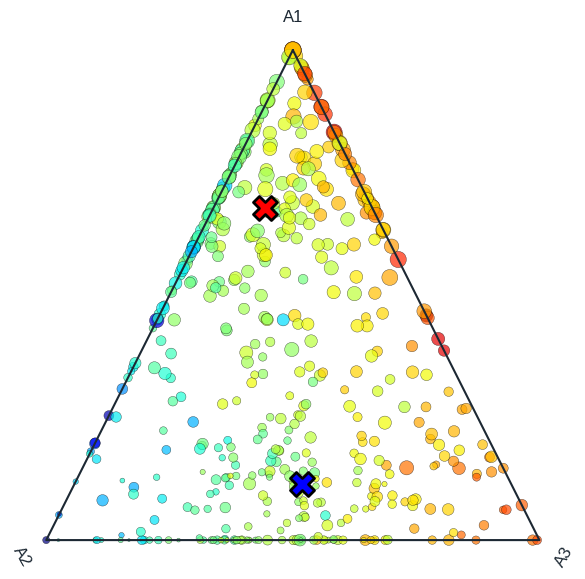

In [102]:
# STEP 1: Get the alfa values for male and female
_ , alfa_male = AA.transform(X_ave_male)
_ , alfa_female = AA.transform(X_ave_female)

# STEP 2: Create Simplex Plot
create_simplex_ax(AA, grid_on = True, 
                  gridcolor = '#EAECEE', 
                  bordercolor='#1C2833', 
                  fontcolor = '#1C2833',
                  fig_size=[7,7])

# STEP 3: Map alfas
mapped_alfa = map_alfa_to_simplex(AA.alfa, AA)
mapped_alfa_male = map_alfa_to_simplex(alfa_male, AA)
mapped_alfa_female = map_alfa_to_simplex(alfa_female, AA)

# STEP 4: Scatter data points
# All data points
df['ChestDiamNorm'] = (df['ChestDiam'] - df['ChestDiam'].min()) / (df['ChestDiam'].max() - df['ChestDiam'].min())
plt.scatter(mapped_alfa[:,0], mapped_alfa[:,1], 
            c = df['Biil'], 
            cmap = 'jet', 
            s = df['ChestDiamNorm'] * 150, 
            alpha = 0.7, 
           edgecolor = 'black')

# Average Male
plt.scatter(mapped_alfa_male[:,0], mapped_alfa_male[:,1], 
            marker = 'X', 
            s = 300, 
            color = 'red', 
            edgecolor = 'black',
            linewidth = 2)

# Average Female
plt.scatter(mapped_alfa_female[:,0], mapped_alfa_female[:,1], 
            marker = 'X', 
            s = 300, 
            color = 'blue', 
            edgecolor = 'black',
            linewidth = 2)

plt.show()

## Plotting profile

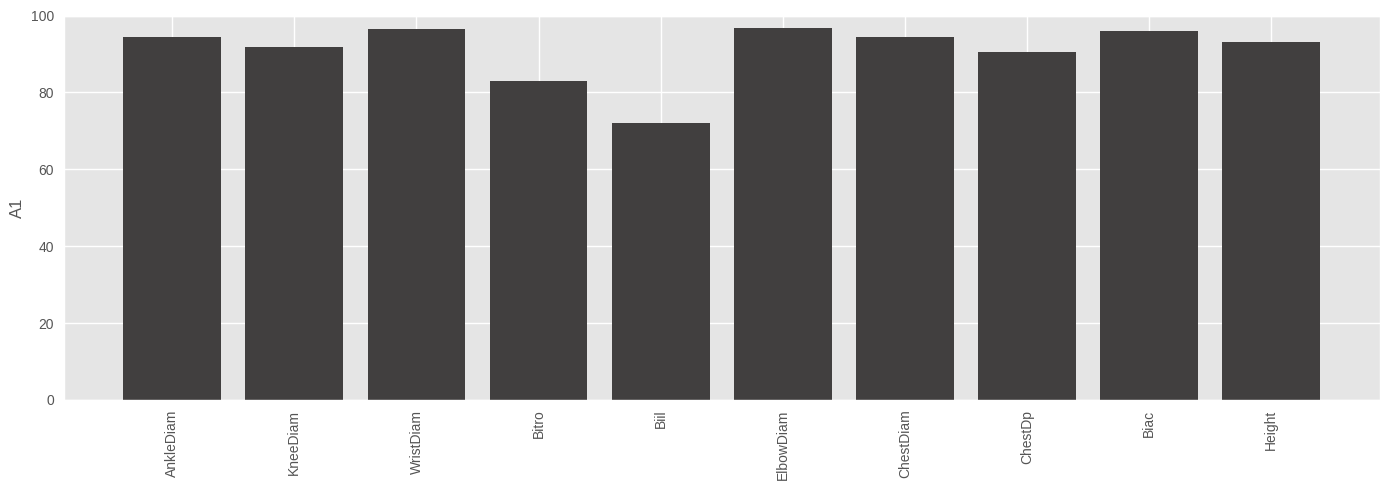

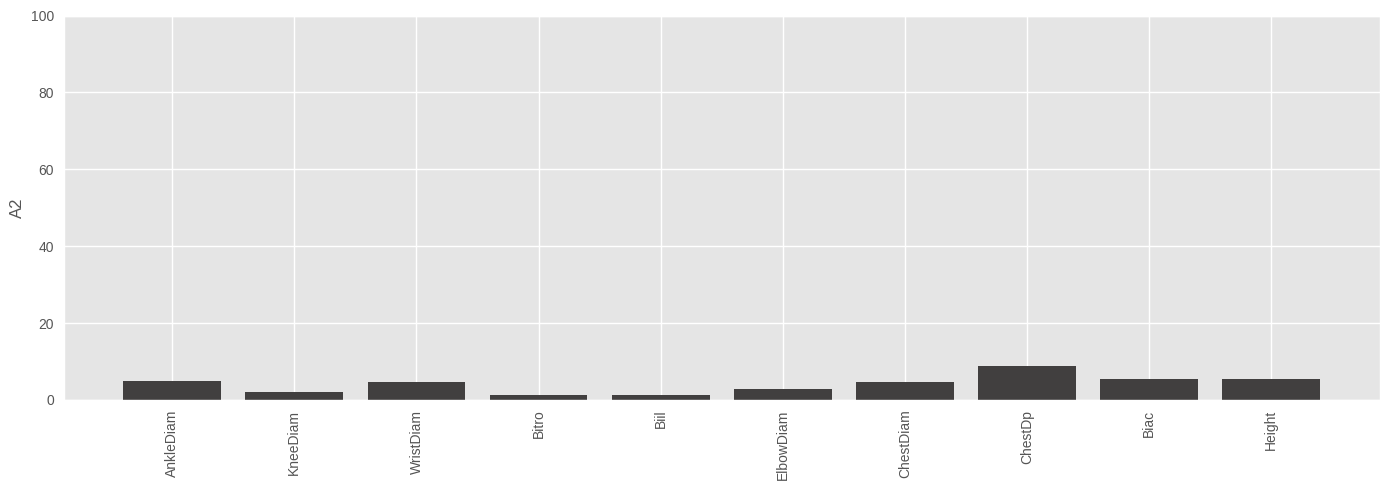

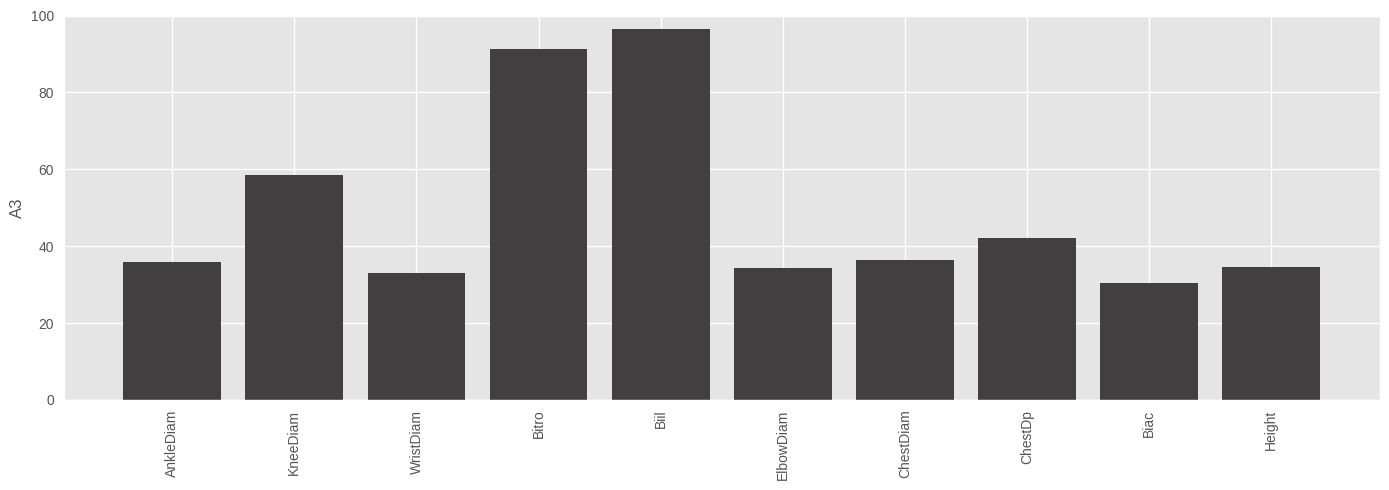

In [112]:
AA.plot_profile(lst_feat)

## Radar plot of profile of archetypes in the feature space

You can also plot the profile of the archetypes in a radar plot. As seen, A1 is extremely high in most features, A2 is extremely low, while A3 is moderate.

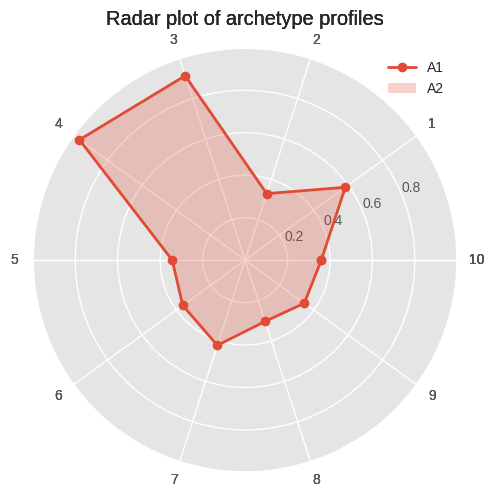

In [119]:
AA.plot_radar_profile(feature_cols=range(11), Title='Radar plot of archetype profiles')

#### Including feature names

You can pass feature names as an argument to get more informed plot.

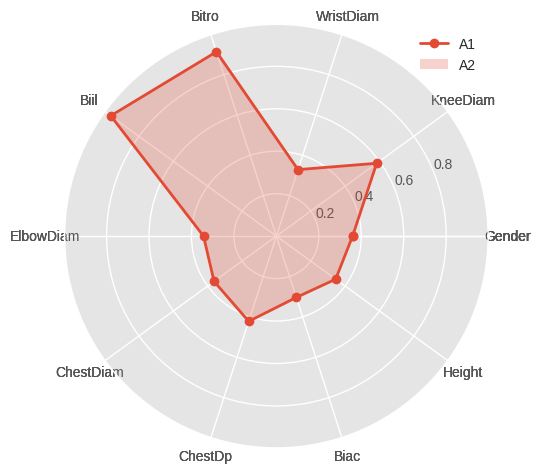

In [118]:
AA.plot_radar_profile(feature_cols=columns, Title='')

## Finding the most archetypal data points in the set

In [120]:
AA._extract_closes_match()

Attribute **.close_match** contains the most archetypal data points. This attribute is a dictionary where the keys are the archetypes. The first item in the tuple gives the index of the data point. The second item is the corresponding $\alpha$ array of that data point. Alfa can used to map the data point to a simplex plot or display it on a radar plot. It also shows how archetypal the data point is. For instance, in this example we see that **archetype 3** has perfect matching data point in the set. 

In [121]:
AA.close_match

{1: (6, array([0.96126367, 0.        , 0.03873633])),
 2: (300, array([0.05130891, 0.94869109, 0.        ])),
 3: (440, array([0.        , 0.00477782, 0.99522218]))}

## Radar plot of archetypal data points in archetype space

It shows the most archetypal data points. As seen, each is inclined toward one archetype.

ValueError: The number of FixedLocator locations (4), usually from a call to set_ticks, does not match the number of labels (3).

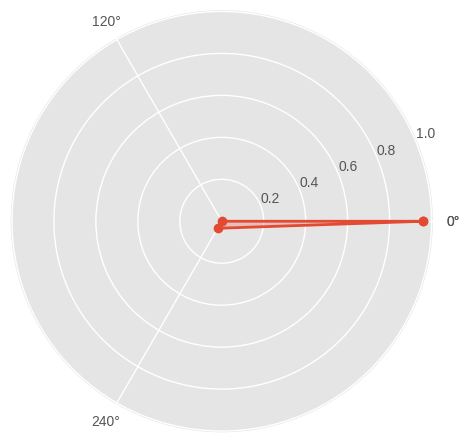

In [124]:
AA.plot_close_match(Title='')

## Radar plot of any data point in archetype space

ValueError: The number of FixedLocator locations (4), usually from a call to set_ticks, does not match the number of labels (3).

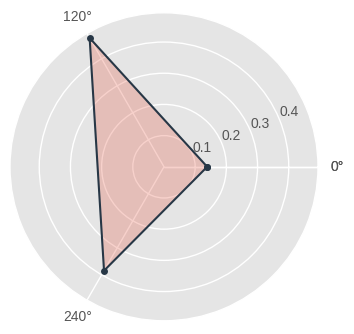

In [125]:
idx = 400
plot_radar_datapoint(AA, X_scaled[idx,:].reshape(1,-1), Title=f'Radar plot of datapoint index = {idx}')

## Parallel axis plot of the data points and archetypes

/home/users/u6853992/Documents/PhD/Workstation/PaperDrafts/BNPclass/archetypes.py:580: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_color.loc[-1] = 'arch'


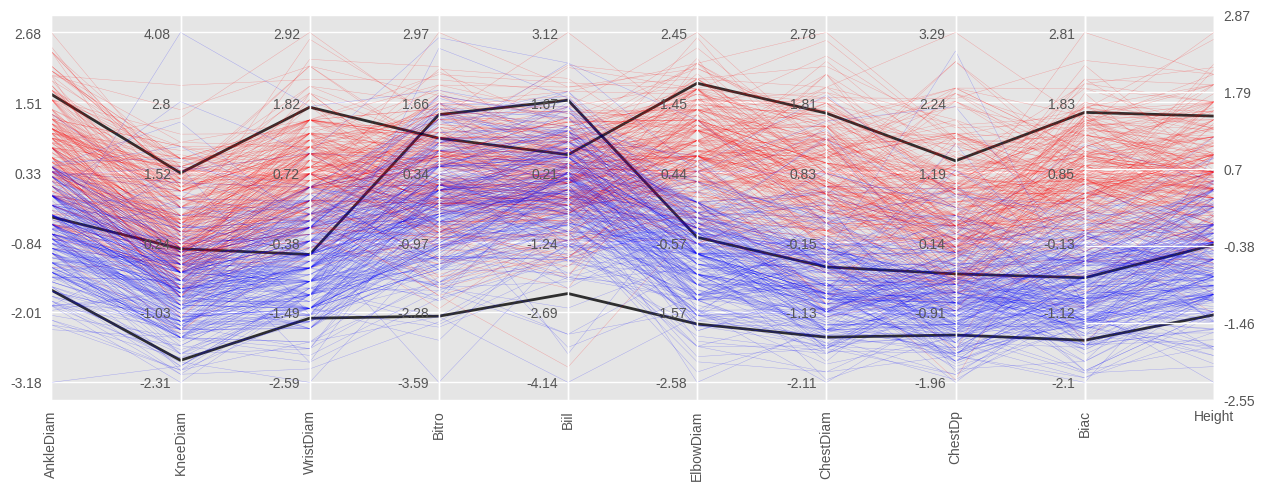

In [29]:
AA.parallel_plot(lst_feat, df_args[['color']], linewidth = '0.3', arch_color = 'black')

# Find an optimal seed number

Note that if you select to **randomly** initialized the archetypes, then the extracted archetypes depend on the initial guess.  Different groups pf archetypes can, together, explain the same variance, but it is possible we might want to find the seed number that maximizes the explained variance. You can use different searching algorithms such as Genetic Algorithm to find the best seed. Here, we simply scan a 1000 seed numbers.<br><br>

**NOTE:** If you select **'furthest_sum'** technique to initialize the archetypes, then, seed number does not have an effect.

In [30]:
seed_numbers = range(1000)
expl_var_old = 0.0
optmal_seed = None

for seed in seed_numbers:    
    AA = ArchetypalAnalysis(n_archetypes = 3, 
                        random_state = seed, 
                        initialize = 'random')
    try:        
        AA.fit(X_scaled)

        if (expl_var_old < AA.explained_variance_):
            expl_var_old = AA.explained_variance_
            optmal_seed = seed
            print(f'Found a new SEED: {seed}: {AA.explained_variance_:12.8f}')
    except:
        print(f'Optimisation failed for SEED: {seed}')

Found a new SEED: 0:   0.73242448
Found a new SEED: 2:   0.73245788
Found a new SEED: 4:   0.73426525
Found a new SEED: 99:   0.73428079


# Additional Exercise:

As an additional excercise you can redo the whole notbook with optimal seed number that was found and see how it impacts the results.